# 7CS133 — Advanced Artificial Intelligence and Machine Learning
## Portfolio Task 2 -- Part A — Model evaluation, validation and principled model selection

**University of Wolverhampton · MSc Computer Science · Module leader: Dr Rahul Mourya**

| | |
|---|---|
| **Assessment** | Portfolio (Assessment 1), Task 2 -- Part A of 3 |
| **Weight** | 5% of the module mark (marked out of 100) |
| **Set** | Teaching Week 3 (in the Thursday lab) |
| **Due** | Friday of Teaching Week 5, 14:00, via Canvas |
| **Learning outcomes** | LO1 (Knowing), LO2 (Doing) |
| **Expected effort** | the 3-hour lab plus roughly 4 hours of your own time |

---

### What this task covers

Three questions, following the Week 3 lecture. They are the three parts of the problem set out on
the last slide of that lecture:

| | | | Marks |
|---|---|---|---|
| **Q1** | **Validate** | A leakage-free pipeline, a splitter that matches deployment, mean ± sd, and the two diagnostic curves | **30** |
| **Q2** | **Measure** | Confusion matrix at a justified threshold; ROC and PR; AUC, AP and Brier; RMSE and MAE for the regression target | **35** |
| **Q3** | **Decide** | Tune with a search, apply the one-standard-error rule, analyse errors by slice, and argue for a model | **35** |

All data is generated with `sklearn` from fixed seeds, so you download nothing and everyone's data
is identical. The real clinical dataset is reserved for the **coursework**.

### What you must submit

1. This notebook, completed, saved as `7CS133_Task2_<your_student_number>.ipynb`
2. An **HTML or PDF export** with **all outputs visible**

Your notebook must run top to bottom without errors on a fresh kernel (`Kernel ▸ Restart & Run All`).
Seeds are fixed for you — do not change `RANDOM_STATE`.

### Rules

* Write your own code. You may use the lecture slides, the scikit-learn user guide and the module reading list.
* Do not copy from other students or from public notebooks. Task 2 work can be discussed in your coursework viva.
* Generative AI may be used to explain concepts or debug errors, but the code and the written answers you submit must be your own. **Declare any use in 3.5.** Undeclared use is an academic-integrity offence.

### How to answer

* Code goes where you see `# ===== YOUR CODE HERE =====`.
* Written answers go in the markdown cells marked ✏️ — double-click to edit. Keep to the word limits; marks are for precision, not length.
* **Self-check** cells are smoke tests: passing means your objects exist and look sensible, not that your answer is right.
* **Quote your own numbers** in every written answer. An answer that would read identically for a different dataset scores in the bottom band.

### The one rule that carries the most marks

The test set is defined for you in Section 0 and is **sealed until Task 3.4**. Every decision —
which model, which hyperparameters, which threshold — is made on cross-validated or validation data.
Touching the test set earlier is the single most expensive mistake available in this task.

---
## Marking scheme (100 marks)

| Question | Part | What it asks | Marks |
|---|---|---|---|
| **Q1** | 1.1 | Leakage-free pipeline; a splitter justified against deployment; mean ± sd for three models | 8 |
| | 1.2 | Quantify what the splitter is worth: grouped against ungrouped, all three models, with a leak check | 8 |
| | 1.3 | Validation curve over model complexity; identify the optimum and read the train–validation gap | 7 |
| | 1.4 | Learning curve; diagnose bias or variance; written answer on what to do next | 7 |
| **Q2** | 2.1 | Threshold chosen on validation data against a stated operating requirement; confusion matrix; the four rates derived by hand | 9 |
| | 2.2 | ROC and PR curves with their own baselines; ROC-AUC and average precision; explain the disagreement | 8 |
| | 2.3 | Brier score and reliability diagram; effect of `class_weight="balanced"` on calibration | 8 |
| | 2.4 | Regression target: RMSE, MAE and $R^2$ against a baseline; interpret the RMSE/MAE ratio | 10 |
| **Q3** | 3.1 | Hyperparameter search under the grouped splitter, with a stated budget | 7 |
| | 3.2 | One-standard-error rule, with "simplest" declared before the results are seen | 6 |
| | 3.3 | Error analysis by slice; identify and size the worst subgroup | 8 |
| | 3.4 | The sealed test set, used exactly once | 4 |
| | 3.5 | Written answer: which model you would deploy and why, plus the GenAI declaration | 10 |

**Within each part, marks are split roughly as:** correctness ~50%, method (no leakage, decisions made
on validation data, sensible metrics) ~25%, interpretation (explains *why*, quotes your own numbers) ~25%.

**Cross-cutting deductions**

| Problem | Penalty |
|---|---|
| Notebook does not run top to bottom | up to −10 |
| Scaling or other fitted preprocessing applied outside the pipeline / before the split | up to −10 |
| Split ignores the patient grouping anywhere a score is reported | up to −10 |
| Test set used for any decision, or evaluated more than once | up to −10 |
| A score reported without its spread, or without a baseline | up to −5 |
| Outputs missing from the export | up to −5 |
| Seeds changed or results not reproducible | up to −5 |

**Grade descriptors (indicative)**

| Mark | Standard |
|---|---|
| 70–100 | All parts correct; the splitter is justified from deployment rather than asserted; curves are diagnosed, not merely plotted; the threshold and the final model choice are argued from the candidate's own numbers; the written answers show real insight into what an estimate can and cannot support |
| 60–69 | All parts essentially correct; minor methodological slips; explanations sound but partly generic |
| 50–59 | Most code works; one substantive methodological error (e.g. tuning on test, or an ungrouped split); explanations describe rather than explain |
| 40–49 | Significant gaps or errors; results reported without spread, baseline or interpretation |
| < 40 | Largely incomplete, or the notebook does not run |

---
# Section 0 — Setup and the case study *(given: do not edit)*

In [12]:
# On Colab or a fresh environment, run this once:
# !pip install -q "scikit-learn>=1.4" matplotlib pandas

In [13]:
# ===== GIVEN — do not edit =====
#
# Everything this notebook needs, grouped by what it is for. You are not
# expected to memorise this list -- but do look up anything unfamiliar in the
# scikit-learn user guide as you meet it.

import numpy as np                 # arrays, masks, random numbers
import pandas as pd                # the results tables you will build
import matplotlib.pyplot as plt    # every plot in this notebook

from sklearn.base import clone                    # an UNFITTED copy of an estimator
from sklearn.dummy import DummyClassifier, DummyRegressor   # the baselines ("the floor")
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier   # Data Mining, Week 2
from sklearn.tree import DecisionTreeClassifier      # Data Mining, Week 2

# Metrics. Note which ones need PROBABILITIES (roc_auc_score, average_precision_score,
# brier_score_loss) and which need hard 0/1 LABELS (precision_score, recall_score,
# confusion_matrix). Passing the wrong one is the most common error in this task.
from sklearn.metrics import (average_precision_score,   # = PR-AUC, for rare positives
                             brier_score_loss,          # calibration: are the probabilities honest?
                             confusion_matrix,          # the four counts everything else comes from
                             mean_absolute_error,
                             precision_recall_curve,    # every threshold at once
                             precision_score, r2_score,
                             recall_score, roc_auc_score,
                             roc_curve,
                             root_mean_squared_error)

# Splitters and the machinery that uses them.
from sklearn.model_selection import (RandomizedSearchCV,     # hyperparameter search (3.1)
                                     StratifiedGroupKFold,   # keeps class balance AND groups
                                     StratifiedKFold,        # keeps class balance only
                                     cross_val_score,
                                     learning_curve,         # score vs TRAINING-SET SIZE (1.4)
                                     train_test_split,
                                     validation_curve)       # score vs ONE HYPERPARAMETER (1.3)

from sklearn.pipeline import Pipeline              # chains preprocessing + model into one estimator
from sklearn.preprocessing import StandardScaler   # must live INSIDE the pipeline, never outside

import sklearn
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# One seed for the whole notebook. Fixing it is what makes your results
# reproducible -- and what lets the marker re-run your work and get your numbers.
RANDOM_STATE = 42          # do not change

plt.rcParams["figure.figsize"] = (6.4, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# University of Wolverhampton palette, so your plots match the lecture slides.
UOW = {"navy": "#1E2A44", "cyan": "#00AEEF", "pink": "#E6337E",
       "green": "#8DC63F", "slate": "#5B6472", "teal": "#45B7A0"}

pandas 3.1.0 | scikit-learn 1.9.1


In [14]:
# ===== GIVEN — the case study =====
#
# A hospital group wants two things from each admission:
#   (i)  will this patient be READMITTED within 30 days?   -> classification
#   (ii) how long will this admission LAST, in days?        -> regression
#
# The data is synthetic but shaped like the real problem:
#   * one row per ADMISSION, and patients have several admissions
#   * each patient carries a persistent signature in feature space
#   * part of each patient's risk is personal and NOT a function of the features
#   * 12 of the 30 columns are pure noise, as in any real extract
#
# READ THIS CELL PROPERLY. Q1.2 asks you to argue about patient grouping, and
# that argument only makes sense if you know how `patient_id` was built and why
# `_personal` exists. Names starting with an underscore are scaffolding you will
# not need again; the names without one are the data you will work with.

_rng = np.random.default_rng(2026)       # one generator -> the whole dataset is reproducible
_n_patients, _p_signal, _p_noise = 1600, 18, 12

# --- Step 1: how many admissions does each patient have? ---------------------
# A draw from {1,2,3,4} per patient. So 1600 patients produce roughly 4300 ROWS.
_stays = _rng.choice([1, 2, 3, 4], size=_n_patients, p=[0.15, 0.30, 0.30, 0.25])

# np.repeat turns per-patient values into per-admission values: patient 0 appears
# _stays[0] times, patient 1 appears _stays[1] times, and so on. The result is
# one patient number per ROW -- this is the GROUP KEY your splitter will need.
patient_id = np.repeat(np.arange(_n_patients), _stays)          # the GROUP key
_n = len(patient_id)                                            # number of admissions

# --- Step 2: features ---------------------------------------------------------
# Each PATIENT gets a fixed point in 18-dimensional space -- their "signature"
# (think: chronic conditions, baseline physiology, the things that do not change
# between admissions).
_signature = _rng.normal(0, 1.0, (_n_patients, _p_signal))

# _signature[patient_id] expands that to one row per ADMISSION (fancy indexing:
# row i of the result is the signature of the patient who had admission i).
# The small added noise is what differs between one stay and the next, so two
# admissions by the same patient sit very close together in feature space.
# >>> That closeness is exactly why an ungrouped split leaks. <<<
_X_signal = _signature[patient_id] + _rng.normal(0, 0.10, (_n, _p_signal))

# 12 columns of pure noise, from a separate generator so they are independent of
# everything above. Real extracts are full of columns that carry no signal; a
# model has to cope with them, and `max_features` in Q3.1 is partly about that.
_X_noise = np.random.default_rng(99).normal(0, 1.0, (_n, _p_noise))

# Stack side by side -> the final 30-column feature matrix, one row per admission.
X = np.column_stack([_X_signal, _X_noise])

# patient- and admission-level attributes, kept aside for the slice analysis in 3.3.
# age_band is a PATIENT property (expanded to rows the same way as the signature);
# admission_type is an ADMISSION property, drawn once per row.
_age_band_patient = _rng.choice(["under 40", "40-70", "over 70"],
                                _n_patients, p=[0.18, 0.45, 0.37])
age_band = _age_band_patient[patient_id]
admission_type = _rng.choice(["emergency", "elective", "referral"],
                             _n, p=[0.45, 0.35, 0.20])

# --- Step 3: the classification target ---------------------------------------
# (i) readmission. The signal is DELIBERATELY weaker for younger patients.
#
# Each patient's risk has two ingredients:
#   _generalisable -- a linear function of the signature. A model CAN learn this,
#                     because it is a pattern in the features.
#   _personal      -- a per-patient random offset. A model can NEVER learn this
#                     from the features, because it is not in them. It can only
#                     be "learned" by recognising the individual -- which is only
#                     possible if that patient also appeared in training.
_beta = _rng.normal(0, 1.0, _p_signal)
_generalisable = _signature @ _beta / np.sqrt(_p_signal)   # @ is matrix multiply
_personal = _rng.normal(0, 2.0, _n_patients)

# _strength scales the learnable part down to a quarter for the under-40 band,
# so the model will genuinely perform worse there. Task 3.3 asks you to find this.
_strength = np.where(_age_band_patient == "under 40", 0.25, 1.0)

# Combine into a log-odds score, then squash to a probability with the logistic
# function 1/(1+e^-z). The -3.55 is an intercept chosen to make readmission rare
# (~15%), as it is in reality.
_logit = 1.9 * _strength * _generalisable + 1.15 * _personal - 3.55
_p_patient = 1.0 / (1.0 + np.exp(-_logit))

# Finally, flip a biased coin per ADMISSION using that patient's probability.
# (rng.random(_n) < p) gives True with probability p; .astype(int) makes it 0/1.
y_readmit = (_rng.random(_n) < _p_patient[patient_id]).astype(int)

# --- Step 4: the regression target -------------------------------------------
# (ii) length of stay, 1-14 days. A baseline of 4.2 days, plus a linear effect of
# the signal features, plus fixed bumps for emergency admissions and for stays
# that end in readmission, plus measurement noise.
_los = (4.2
        + _X_signal @ (_rng.normal(0, 1.0, _p_signal) / np.sqrt(_p_signal)) * 2.4
        + 1.9 * (admission_type == "emergency")   # bool array -> 1.0 / 0.0 in arithmetic
        + 0.8 * y_readmit
        + _rng.normal(0, 1.8, _n))

# np.rint rounds to the nearest whole day; np.clip keeps it inside 1..14.
y_los = np.clip(np.rint(_los), 1, 14).astype(int)

# Column names, so you can tell signal from noise if you inspect coefficients
# or feature importances. In a real extract you would not have this luxury.
feature_names = ([f"sig_{i:02d}" for i in range(_p_signal)]
                 + [f"noise_{i:02d}" for i in range(_p_noise)])

print("admissions        :", X.shape)
print("distinct patients :", len(np.unique(patient_id)))
print("readmitted within 30 days : {:.3f}".format(y_readmit.mean()))
print("length of stay    : mean {:.2f} days, sd {:.2f}, range {}-{}"
      .format(y_los.mean(), y_los.std(), y_los.min(), y_los.max()))

admissions        : (4295, 30)
distinct patients : 1600
readmitted within 30 days : 0.149
length of stay    : mean 5.31 days, sd 2.72, range 1-14


In [15]:
# ===== GIVEN — the sealed test set. Do not touch it before Task 3.4. =====
#
# The split is by PATIENT, so no patient appears on both sides of it.
# Splitting rows at random would put some of a patient's admissions in
# development and the rest in test, and your final number would be inflated for
# exactly the reason Q1.2 asks you to measure.

# Split the PATIENT NUMBERS (0..1599), not the rows.
_dev_patients, _test_patients = train_test_split(
    np.arange(_n_patients), test_size=0.30, random_state=RANDOM_STATE)

# np.isin(a, b) -> a boolean array, True wherever the value in `a` appears in `b`.
# So is_test is True for every ADMISSION belonging to a test patient.
is_test = np.isin(patient_id, _test_patients)

# `~` inverts a boolean mask, so X[~is_test] is "all rows that are NOT test".
# Keep the three arrays for each side aligned: features, labels, and the group key.
X_dev,  y_dev,  g_dev  = X[~is_test], y_readmit[~is_test], patient_id[~is_test]
X_test, y_test, g_test = X[is_test],  y_readmit[is_test],  patient_id[is_test]

# The regression target and the slice attributes, split the same way.
los_dev, los_test = y_los[~is_test], y_los[is_test]
age_dev, age_test = age_band[~is_test], age_band[is_test]
adm_dev, adm_test = admission_type[~is_test], admission_type[is_test]

print("development : {} admissions, {} patients, {:.3f} positive"
      .format(len(y_dev), len(np.unique(g_dev)), y_dev.mean()))
print("test (SEALED): {} admissions, {} patients, {:.3f} positive"
      .format(len(y_test), len(np.unique(g_test)), y_test.mean()))

# np.intersect1d returns the values present in BOTH arrays. An empty result means
# no patient is on both sides. This is the contract the rest of the task relies on.
assert len(np.intersect1d(g_dev, g_test)) == 0

development : 3020 admissions, 1120 patients, 0.143 positive
test (SEALED): 1275 admissions, 480 patients, 0.165 positive


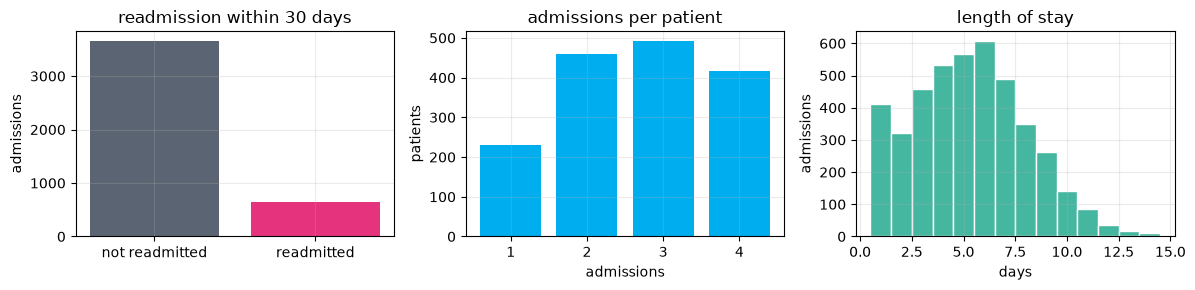

col_0         0      1
row_0                 
40-70     0.844  0.156
over 70   0.842  0.158
under 40  0.884  0.116


In [16]:
# ===== GIVEN — a first look =====
# Three pictures worth having in your head before you model anything.

fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))

# (1) How rare is the positive class? This sets the PR baseline you must beat,
#     and it is why accuracy would be a useless metric here (Week 2).
axes[0].bar(["not readmitted", "readmitted"],
            [(y_readmit == 0).sum(), (y_readmit == 1).sum()],
            color=[UOW["slate"], UOW["pink"]])
axes[0].set(title="readmission within 30 days", ylabel="admissions")

# (2) How much repetition is there?
#     np.bincount(patient_id)      -> admissions per patient  (length 1600)
#     np.bincount(of that)         -> how many patients have 0, 1, 2, ... admissions
#     [1:]                         -> drop the "0 admissions" entry, which is empty
counts = np.bincount(np.bincount(patient_id))[1:]
axes[1].bar(np.arange(1, len(counts) + 1), counts, color=UOW["cyan"])
axes[1].set(title="admissions per patient", xlabel="admissions", ylabel="patients")

# (3) The regression target. Bin edges at 0.5, 1.5, ... centre each bar on a whole day.
axes[2].hist(y_los, bins=np.arange(0.5, 15.5), color=UOW["teal"],
             edgecolor="white")
axes[2].set(title="length of stay", xlabel="days", ylabel="admissions")
plt.tight_layout(); plt.show()

# Readmission rate within each age band. normalize="index" makes each ROW sum to 1,
# so the right-hand column is the positive rate for that band. Note that the rates
# are similar -- the bands differ in how PREDICTABLE they are, not in how often
# readmission happens. Keep that in mind when you reach Task 3.3.
print(pd.crosstab(age_band, y_readmit, normalize="index").round(3))

---
# Q1 — Part A: Validate *(30 marks)*

Before any number means anything, the estimate that produced it has to be honest. In this part you
build the pipeline, choose a splitting strategy you can justify from how the model will be used, and
run the two diagnostic curves.

### Task 1.1 — A leakage-free pipeline and a defensible splitter *(8 marks)*

Build three estimators and cross-validate all of them: the **logistic pipeline** from Week 2, a
**decision tree** and **$k$-nearest neighbours** (both from Week 2 of Data Mining). Report
**mean ± standard deviation** of average precision (PR-AUC) — a bare mean scores zero for this part.

The three are chosen deliberately. They sit at very different points on the
memorise-versus-generalise spectrum, and Task 1.2 is about what that difference costs you if the
split is wrong.

Requirements:

* every fitted step (scaling, and anything else you add) lives **inside** a `Pipeline`, so it is
  refitted within each fold;
* the splitter must reflect the fact that the model will be used on **patients it has never seen**;
* report the `DummyClassifier` floor alongside, so the numbers can be read.

In [17]:
def make_logistic(C=1.0, **kwargs):
    "Imbalance-aware regularised logistic regression, scaler inside the pipeline."

    params = {
        "C": C,
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": RANDOM_STATE,
    }
    params.update(kwargs)

    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(**params))
    ])


def make_tree(**kwargs):
    # A single decision tree (Data Mining, Week 2). Trees split one feature at a
    # time, so they need no scaling -- but pass class_weight="balanced" for the
    # same reason the logistic model does, and set random_state for reproducibility.
    # Accept **kwargs so Task 3.1 can pass tuned hyperparameters straight through.
    return Pipeline([
        ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **kwargs))
    ])



def make_knn(**kwargs):
    # k-nearest neighbours (Data Mining, Week 2). It predicts a row from the rows
    # closest to it, so the distance metric is everything: an unscaled feature with
    # a large range would dominate every distance. The scaler must therefore be
    # INSIDE the pipeline, refitted per fold, exactly as for the logistic model.
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(**kwargs))
    ])

# The splitter. Think about what must NOT be shared between train and validation.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state= RANDOM_STATE)
cv_results = {}     # name -> array of per-fold PR-AUC scores
for name, est in [("logistic", make_logistic()),
                  ("decision tree", make_tree()),
                  ("k-nearest neighbours", make_knn()),
                  ("dummy", DummyClassifier(strategy="stratified",
                                            random_state=RANDOM_STATE))]:
    
    scores = cross_val_score(est, X_dev,y_dev, groups=g_dev, cv=cv, scoring='average_precision')
    cv_results[name] = scores

    # Report mean ± standard deviation
    print(f"{name:20} PR-AUC: {np.mean(scores):.3f} ± {np.std(scores):.3f}")

logistic             PR-AUC: 0.315 ± 0.036
decision tree        PR-AUC: 0.156 ± 0.013
k-nearest neighbours PR-AUC: 0.168 ± 0.015
dummy                PR-AUC: 0.146 ± 0.004


In [18]:
# ===== SELF-CHECK 1.1 =====
# What this checks: that your two factories return usable estimators, that the
# scaler is inside a Pipeline (not applied beforehand), that you defined a
# splitter, and that you scored all three estimators once per fold.
# What it does NOT check: whether your splitter is the RIGHT one. That is the
# marked judgement, and Task 1.2 is where it gets tested empirically.

assert all(f() is not None for f in (make_logistic, make_tree, make_knn)), \
    "All three factories must return an estimator."

# If these fail you have probably scaled X_dev yourself before cross-validating.
# That leaks: the scaler would see every fold's validation rows while fitting.
# k-NN is a DISTANCE-based method, so it needs scaling just as much as the linear
# model does. A decision tree does not -- it splits one feature at a time, and a
# monotone rescaling of a feature cannot change where the splits fall.
assert isinstance(make_logistic(), Pipeline), "The logistic model must be a Pipeline."
assert isinstance(make_knn(), Pipeline), "k-NN uses distances, so it needs the scaler inside a Pipeline."

assert cv is not None and cv.get_n_splits() >= 5, "Define a cross-validation splitter with at least 5 folds."
assert set(cv_results) == {"logistic", "decision tree", "k-nearest neighbours", "dummy"}, \
    "Score all four estimators."

# One score per fold -- a single number means you averaged too early and have
# thrown away the spread, which is half of what you are asked to report.
assert all(len(v) == cv.get_n_splits() for v in cv_results.values()), "One score per fold."

print("PR-AUC, {}-fold                    mean      sd".format(cv.get_n_splits()))
for name, s in cv_results.items():
    print("  {:<28s}  {:.3f}   {:.3f}".format(name, s.mean(), s.std()))

# For average precision, random guessing scores the PREVALENCE, not 0.5.
# Every model number above should be read against this line.
print("\nprevalence (the PR floor)  : {:.3f}".format(y_dev.mean()))

PR-AUC, 5-fold                    mean      sd
  logistic                      0.315   0.036
  decision tree                 0.156   0.013
  k-nearest neighbours          0.168   0.015
  dummy                         0.146   0.004

prevalence (the PR floor)  : 0.143


### Task 1.2 — What is the splitter worth? *(8 marks)*

Quantify the decision you just made. Re-score **all three** real models under a splitter that
ignores the patient grouping, and compare. Then prove your chosen splitter does what you claim: no
patient may appear on both sides of any fold.

Fill in `inflation_table` with one row per model.

Before you run it, predict the ordering. Which of the three can recognise *an individual patient*
from their features, and which can only learn *a pattern across patients*? The size of each model's
inflation should follow directly from that answer.

In [19]:
cv_ungrouped = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

builders = {"logistic": make_logistic,
            "decision tree": make_tree,
            "k-nearest neighbours": make_knn}

rows = []
for name, build in builders.items():
    est = build()
    # score `est` under cv_ungrouped (no groups) and under your `cv` (with groups),
    ungrouped_scores = cross_val_score(est, X_dev,y_dev,cv=cv_ungrouped, scoring='average_precision')

    # then append (name, ungrouped_mean, grouped_mean, ungrouped_mean - grouped_mean)    
    rows.append([name, ungrouped_scores.mean(),cv_results[name].mean(), ungrouped_scores.mean() - cv_results[name].mean()])

inflation_table = pd.DataFrame(
    rows, columns=["model", "ungrouped", "grouped", "inflation"])

# Prove the grouped splitter keeps each patient in a single fold.
shared_patients = 0

for train_idx, val_idx in cv.split(X_dev, y_dev, groups=g_dev):
    train_patients = g_dev[train_idx]
    val_patients = g_dev[val_idx]

    overlap = np.intersect1d(train_patients, val_patients)
    shared_patients += len(overlap)  

#(total across all folds)

In [ ]:
# ===== SELF-CHECK 1.2 =====
# What this checks: that you produced all three comparisons, that your chosen
# splitter genuinely keeps each patient inside one fold, and that the ungrouped run
# really was ungrouped (if the inflation is near zero for every model, you probably
# passed groups= to both runs, or to neither).

assert len(inflation_table) == 3, "One row per model."
assert shared_patients is not None, "Count the patients shared between train and validation."

# This is a test of the SPLITTER's contract, not of any model: summed over folds,
# no patient may appear in a training part and its own validation part.
assert shared_patients == 0, "Your splitter is leaking patients across folds."

print(inflation_table.round(3).to_string(index=False))
print("\nprevalence floor : {:.3f}".format(y_dev.mean()))
print("patients shared between train and validation, summed over folds: {}"
      .format(shared_patients))

# k-NN predicts a row from the rows nearest to it. Two admissions by the same
# patient sit almost on top of each other in feature space (Section 0), so under an
# ungrouped split a stay's nearest neighbour is very often THE SAME PATIENT'S other
# stay -- the model is doing lookup, not learning. Grouping removes that shortcut.
# The linear model has no such shortcut available and should barely move.
# Read all three rows against the prevalence floor before answering 1.4.
knn_row = inflation_table.set_index("model").loc["k-nearest neighbours"]
assert knn_row["inflation"] > 0.10, \
    "Expected a large inflation for k-NN -- check that groups= was passed only to the grouped run."

               model  ungrouped  grouped  inflation
            logistic      0.321    0.315      0.007
       decision tree      0.198    0.156      0.042
k-nearest neighbours      0.272    0.168      0.104

prevalence floor : 0.143
patients shared between train and validation, summed over folds: 0


### Task 1.3 — Validation curve *(7 marks)*

Sweep **one** complexity knob of the decision tree — `min_samples_leaf` — under your grouped
splitter, and plot training and validation scores against it.

Note the direction: `min_samples_leaf = 1` lets every leaf hold a single admission (maximum
complexity); large values force coarse leaves (minimum complexity). So the complexity axis runs
**right to left**.

In [21]:
leaf_grid = [1, 2, 5, 10, 25, 50, 100, 200, 400]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state= RANDOM_STATE)

train_leaf, val_leaf = validation_curve(
    estimator=make_tree(),
    X=X_dev,
    y=y_dev,
    param_name="model__min_samples_leaf",
    param_range=leaf_grid,
    cv=cv,
    groups=g_dev,
    scoring="average_precision",
)

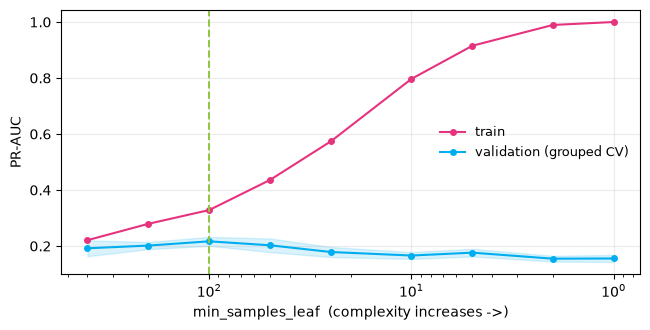

  leaf    train    validation (mean +/- sd)
     1    1.000    0.156 +/- 0.013
     2    0.989    0.155 +/- 0.010
     5    0.915    0.176 +/- 0.014
    10    0.797    0.166 +/- 0.012
    25    0.574    0.179 +/- 0.018
    50    0.436    0.203 +/- 0.024
   100    0.329    0.217 +/- 0.016   <- best
   200    0.279    0.202 +/- 0.013
   400    0.221    0.192 +/- 0.028

train-validation gap at min_samples_leaf=1 : 0.844
train-validation gap at the optimum        : 0.112


In [22]:
# ===== SELF-CHECK 1.3 =====
# What this checks: that validation_curve ran over the right grid and returned
# one score per (grid value, fold). It cannot check that you read the plot
# correctly -- that is what the written answer is for.

assert train_leaf is not None and val_leaf is not None, "Compute the validation curve."

# validation_curve returns two arrays shaped (n_grid_values, n_folds).
# Rows = the values you swept; columns = the folds. So .mean(axis=1) averages
# ACROSS FOLDS and leaves one number per grid value.
assert train_leaf.shape == (len(leaf_grid), cv.get_n_splits()), \
    "Expected one row per grid value and one column per fold."

mu_leaf = val_leaf.mean(axis=1)      # mean validation score at each grid value
sd_leaf = val_leaf.std(axis=1)       # spread across folds -- the shaded band below
best_leaf_i = int(mu_leaf.argmax())  # index of the best grid value

plt.figure(figsize=(6.6, 3.4))
plt.semilogx(leaf_grid, train_leaf.mean(axis=1), "-o", ms=4,
             color=UOW["pink"], label="train")
plt.semilogx(leaf_grid, mu_leaf, "-o", ms=4, color=UOW["cyan"],
             label="validation (grouped CV)")
# The shaded band is +/- one standard deviation across folds. Differences smaller
# than this band are not differences.
plt.fill_between(leaf_grid, mu_leaf - sd_leaf, mu_leaf + sd_leaf,
                 color=UOW["cyan"], alpha=0.15)
plt.axvline(leaf_grid[best_leaf_i], ls="--", color=UOW["green"], lw=1.4)

# min_samples_leaf=1 is the MOST complex tree and 400 the least, so the axis is
# reversed to put complexity on the right, matching the lecture's curves.
plt.gca().invert_xaxis()          # complexity increases to the right
plt.xlabel("min_samples_leaf  (complexity increases ->)")
plt.ylabel("PR-AUC"); plt.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

print("  leaf    train    validation (mean +/- sd)")
for L, t, m, s in zip(leaf_grid, train_leaf.mean(axis=1), mu_leaf, sd_leaf):
    print("  {:4d}    {:.3f}    {:.3f} +/- {:.3f}{}"
          .format(L, t, m, s, "   <- best" if m == mu_leaf.max() else ""))

# The GAP between the two curves is the variance of the model; the HEIGHT of the
# training curve is roughly its bias. Compare these two numbers -- the first is a
# tree grown until every leaf is pure (it has memorised its training data), the
# second a tree coarse enough to generalise.
#
# A tree with min_samples_leaf=1 scores 1.000 on its own training data by
# construction: it keeps splitting until no leaf contains both classes. That is
# worth remembering whenever you see a perfect training score.
print("\ntrain-validation gap at min_samples_leaf=1 : {:.3f}"
      .format(train_leaf.mean(axis=1)[0] - mu_leaf[0]))
print("train-validation gap at the optimum        : {:.3f}"
      .format(train_leaf.mean(axis=1)[best_leaf_i] - mu_leaf[best_leaf_i]))

### Task 1.4 — Learning curve and diagnosis *(7 marks)*

Now hold a model fixed and vary the amount of training data. Use the **logistic** pipeline with
`C=0.1` and your grouped splitter.

*(This cell fits 7 × 5 = 35 models; expect 20–40 seconds.)*

In [23]:
size_grid = np.linspace(0.15, 1.0, 7)

lc_sizes, lc_train, lc_val = learning_curve(
    estimator=make_logistic(C=0.1),
    X=X_dev,
    y=y_dev,
    train_sizes=size_grid,
    cv=cv,
    groups=g_dev,
    scoring="average_precision",
    shuffle=True,
    random_state=RANDOM_STATE,
)

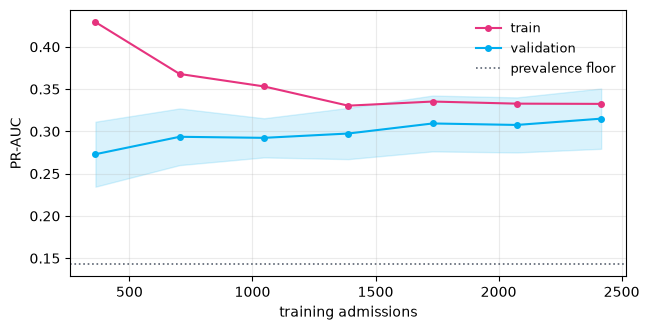

smallest training set: train 0.429  validation 0.273  gap 0.156
largest  training set: train 0.333  validation 0.315  gap 0.017
validation rise across the range: +0.042


In [24]:
# ===== SELF-CHECK 1.4 =====
# What this checks: that learning_curve ran and returned one point per training
# size. The diagnosis is yours to make, in the written answer below.

assert lc_sizes is not None, "Compute the learning curve."
assert len(lc_sizes) == len(size_grid), "One point per training size."

# Same shape convention as the validation curve: (n_sizes, n_folds).
# lc_sizes holds the ACTUAL number of training rows used at each point.
tr_m, va_m = lc_train.mean(axis=1), lc_val.mean(axis=1)

plt.figure(figsize=(6.6, 3.4))
plt.plot(lc_sizes, tr_m, "-o", ms=4, color=UOW["pink"], label="train")
plt.plot(lc_sizes, va_m, "-o", ms=4, color=UOW["cyan"], label="validation")
plt.fill_between(lc_sizes, lc_val.mean(1) - lc_val.std(1),
                 lc_val.mean(1) + lc_val.std(1), color=UOW["cyan"], alpha=0.15)
# The floor a model that learned nothing would reach, for reference.
plt.axhline(y_dev.mean(), ls=":", color=UOW["slate"], lw=1.2, label="prevalence floor")
plt.xlabel("training admissions"); plt.ylabel("PR-AUC")
plt.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

# Read these three numbers together:
#   * a training score that FALLS as data grows is normal -- fitting 400 rows well
#     is easy, fitting 3,000 is hard;
#   * a gap that CLOSES means variance is being cured by data;
#   * a validation curve that has FLATTENED means more rows will not help, however
#     much you collect.
print("smallest training set: train {:.3f}  validation {:.3f}  gap {:.3f}"
      .format(tr_m[0], va_m[0], tr_m[0] - va_m[0]))
print("largest  training set: train {:.3f}  validation {:.3f}  gap {:.3f}"
      .format(tr_m[-1], va_m[-1], tr_m[-1] - va_m[-1]))
print("validation rise across the range: {:+.3f}".format(va_m[-1] - va_m[0]))

#### ✏️ Written answer 1.4 *(part of the 7 marks)* — replace this text

**Up to 200 words.** Using the numbers printed above:

1. Is this model limited more by bias or by variance at the largest training size? Say what in the
   two curves tells you.

**Mohammed Grech**:
As training size increases, the training AP curve falls from 0.429 to 0.333, while the validation AP curve rises from 0.273 to 0.315. The gap between these two curves decreases from 0.156 to 0.017. This indicates that adding data reduces overfitting. Training performance decreases, but performance on unseen patients improves. At the largest training size, the small remaining gap suggests that high variance is no longer the main limitation. The model appears more limited by bias or the available predictive signal.

2. Would another 3,000 admissions be a good investment for this model? Justify from the shape of
   the validation curve, not from intuition.

**Mohammed Grech**: More data may help, but the curve suggests diminishing returns. Validation AP rises from 0.273 to 0.315 overall, while increasing training size from 1,732 to 2,417 improves it only from 0.309 to 0.315. The curve has not completely flattened, but it does not justify expecting a large improvement from another 3,000 admissions. Improving features or investigating another model may be more worthwhile.

3. Task 1.3 showed a very large train–validation gap for the tree at `min_samples_leaf=1`.
   Name the single change to the *split* that would have hidden part of that gap, and say why.

**Mohammed Grech**: Replacing grouped splitting with an ungrouped admission-level split would hide part of the gap. Admissions from the same patient could appear in both training and validation. As a result, the tree could recognise familiar patient patterns, artificially increasing validation performance and making overfitting seem less severe.

*Your answer:*

---
# Q2 — Part B: Measure *(35 marks)*

You now have honest estimates. This part is about reporting them: the right metrics, computed
correctly, against the right baselines.

Tasks 2.1–2.3 use the **classification** target (readmission); Task 2.4 uses the **regression**
target (length of stay).

### Task 2.1 — A justified threshold and the four rates *(9 marks)*

The clinical team states the requirement: **"catch at least 70% of readmissions."** Everything else
is negotiable.

1. Split `X_dev` into a training part and a validation part **by patient** (a random row split would
   undo Task 1.1).
2. Fit the logistic pipeline on the training part.
3. Choose the threshold `t_star` that meets the recall requirement on the **validation** part, at the
   best precision available.
4. Apply it to the validation part and build the confusion matrix. Derive precision, recall,
   specificity and FPR **by hand** from `tn, fp, fn, tp` — no scikit-learn metric functions for those four.

The test set stays sealed.

In [25]:
# Split patient IDs, keeping each patient's admissions together.
fit_patients, val_patients = train_test_split(
    np.unique(g_dev),
    test_size=0.25,
    random_state=RANDOM_STATE,
)

# All admissions belonging to the patients
fit_mask = np.isin(g_dev, fit_patients)
val_mask = np.isin(g_dev, val_patients)

# Train only on the training patients. X_dev[fit_mask] contains the training patients’ admissions.
model_b = make_logistic().fit(
    X_dev[fit_mask],
    y_dev[fit_mask],
)

# Get predicted readmission probabilities for validation patients.
p_val = model_b.predict_proba(X_dev[val_mask])[:, 1]

In [26]:
y_val_true = y_dev[val_mask]

precisions, recalls, thresholds = precision_recall_curve(
    y_val_true,
    p_val,
)

# Find thresholds that catch at least 70% of actual readmissions.
eligible = np.flatnonzero(recalls[:-1] >= 0.70)

# Choose the highest threshold that still meets the requirement.
t_star = thresholds[eligible[-1]]

y_val_true = y_dev[val_mask]
y_val_pred = (p_val >= t_star).astype(int)

tn, fp, fn, tp = confusion_matrix(y_val_true, y_val_pred).ravel()

my_precision = tp / (tp + fp)
my_recall = tp / (tp + fn)
my_specificity = tn / (tn + fp)
my_fpr = fp / (fp + tn)

print("Confusion matrix: rows = actual, columns = predicted")
print(np.array([[tn, fp], [fn, tp]]))

Confusion matrix: rows = actual, columns = predicted
[[430 219]
 [ 30  71]]


In [27]:
# ===== SELF-CHECK 2.1 =====
# What this checks: that your fit/validation split respects patients, that you
# chose a threshold at all, that it meets the stated clinical requirement, and
# that your four rates are ARITHMETICALLY right. The tolerance is 1e-9 because
# these should agree exactly -- they are the same four counts, divided the same
# way. A mismatch means a wrong denominator, not a rounding difference.

assert fit_mask is not None and val_mask is not None, "Build the two masks."
assert len(np.intersect1d(g_dev[fit_mask], g_dev[val_mask])) == 0, \
    "Your fit/validation split shares patients -- split by patient, not by row."
assert t_star is not None, "Choose a threshold."
assert my_precision is not None, "Fill in the four rates."

# precision = TP / (TP + FP): the denominator is what the MODEL called positive.
assert abs(my_precision - precision_score(y_val_true, y_val_pred)) < 1e-9, \
    "precision disagrees with sklearn -- check the denominator (predicted positives)."

# recall = TP / (TP + FN): the denominator is what was REALLY positive.
assert abs(my_recall - recall_score(y_val_true, y_val_pred)) < 1e-9, \
    "recall disagrees with sklearn -- check the denominator (actual positives)."

# The clinical requirement was "catch at least 70%". If this fails, your threshold
# is too strict -- lower it until recall clears 0.70, then take the best precision.
assert my_recall >= 0.70 - 1e-9, "The threshold must meet the stated recall requirement."

# FPR and specificity are two views of the same column of the confusion matrix.
assert abs(my_fpr - (1 - my_specificity)) < 1e-12, "FPR should equal 1 - specificity."

print("threshold t*  {:.3f}".format(t_star))
print("prevalence    {:.3f}".format(y_val_true.mean()))
print("precision     {:.3f}".format(my_precision))
print("recall        {:.3f}".format(my_recall))
print("specificity   {:.3f}    FPR {:.3f}".format(my_specificity, my_fpr))

# This last line is the one a ward manager would actually care about: it converts
# precision into a workload. Quote it in your written answer.
print("\nTo catch {} true readmissions we flag {} admissions -- {:.1f} per true case."
      .format(tp, tp + fp, (tp + fp) / tp))

threshold t*  0.516
prevalence    0.135
precision     0.245
recall        0.703
specificity   0.663    FPR 0.337

To catch 71 true readmissions we flag 290 admissions -- 4.1 per true case.


### Task 2.2 — ROC and PR, each against its own baseline *(8 marks)*

Plot both curves for the same validation predictions, mark the operating point from 2.1 on each, and
report ROC-AUC and average precision.

The two baselines are **not** the same line: chance is 0.5 for ROC and the **prevalence** for PR.
A PR curve plotted without its prevalence line is uninterpretable.

In [28]:
fpr_c, tpr_c, _ = roc_curve(y_val_true, p_val)

prec_c, rec_c, _ = precision_recall_curve(y_val_true, p_val)

auc_roc = roc_auc_score(y_val_true, p_val)

auc_pr = average_precision_score(y_val_true, p_val)

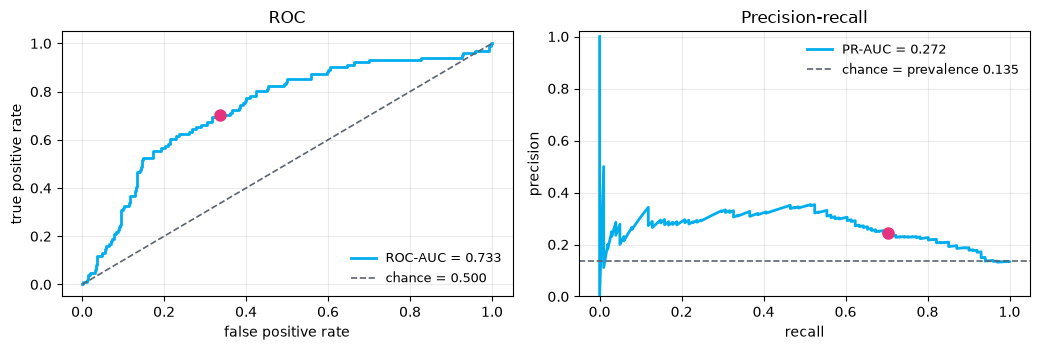

ROC-AUC 0.733  (chance 0.500)   |   PR-AUC 0.272  (chance 0.135)
ratio to chance:  ROC 1.47x   PR 2.02x


In [29]:
# ===== SELF-CHECK 2.2 =====
# What this checks: that both summary numbers exist and clear their own baselines.
# Note that the two baselines are DIFFERENT -- 0.5 for ROC-AUC regardless of class
# balance, but the prevalence for average precision. A PR curve drawn without its
# prevalence line cannot be interpreted.

assert auc_roc is not None and auc_pr is not None, "Compute both summaries."
prevalence = y_val_true.mean()
assert 0.5 < auc_roc < 1.0, "ROC-AUC should beat chance."
assert auc_pr > prevalence, "Average precision should beat the prevalence floor."

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.6))

# Left: ROC. The diagonal is random guessing. Each point on the curve is one
# threshold, so the whole curve is "every decision you could have made".
a1.plot(fpr_c, tpr_c, color=UOW["cyan"], lw=2, label=f"ROC-AUC = {auc_roc:.3f}")
a1.plot([0, 1], [0, 1], ls="--", color=UOW["slate"], lw=1.2, label="chance = 0.500")
# The pink dot is the threshold you actually chose in 2.1 -- the same operating
# point appears on both panels, which is what makes the comparison honest.
a1.plot(my_fpr, my_recall, "o", color=UOW["pink"], ms=8)
a1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
a1.legend(frameon=False, fontsize=9, loc="lower right")

# Right: precision-recall, same predictions, same thresholds, different axes.
a2.plot(rec_c, prec_c, color=UOW["cyan"], lw=2, label=f"PR-AUC = {auc_pr:.3f}")
a2.axhline(prevalence, ls="--", color=UOW["slate"], lw=1.2,
           label=f"chance = prevalence {prevalence:.3f}")
a2.plot(my_recall, my_precision, "o", color=UOW["pink"], ms=8)
a2.set(xlabel="recall", ylabel="precision", title="Precision-recall", ylim=(0, 1.02))
a2.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

print("ROC-AUC {:.3f}  (chance 0.500)   |   PR-AUC {:.3f}  (chance {:.3f})"
      .format(auc_roc, auc_pr, prevalence))

# Each metric divided by ITS OWN baseline. This is the fair comparison, and it
# usually tells a different story from the raw numbers. Use it in your answer.
print("ratio to chance:  ROC {:.2f}x   PR {:.2f}x"
      .format(auc_roc / 0.5, auc_pr / prevalence))

### Task 2.3 — Are the probabilities honest? *(8 marks)*

ROC-AUC and average precision both score the **ranking**. Neither notices whether the numbers the
model calls probabilities mean anything.

Compute the Brier score for your model, and for a second copy of the same pipeline fitted
**without** `class_weight="balanced"`. Then draw the reliability diagram for both.

In [30]:
from sklearn.calibration import calibration_curve
# Fit the same pipeline without class weighting.
model_plain = make_logistic(class_weight=None).fit(
    X_dev[fit_mask],
    y_dev[fit_mask],
)

# Predict probabilities for the same validation admissions.
p_val_plain = model_plain.predict_proba(
    X_dev[val_mask]
)[:, 1]

# Compare probability prediction errors.
brier_balanced = brier_score_loss(y_val_true, p_val)
brier_plain = brier_score_loss(y_val_true, p_val_plain)

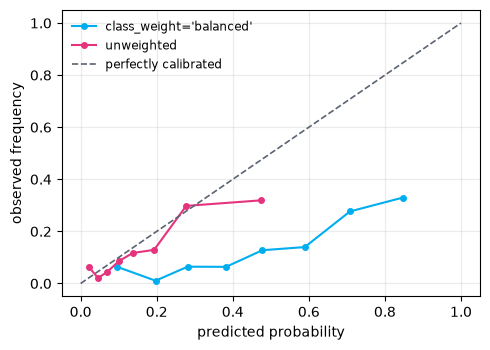

Brier score (lower is better)
  class_weight='balanced' : 0.2272
  unweighted              : 0.1121

ranking quality, same two models (ROC-AUC)
  class_weight='balanced' : 0.733
  unweighted              : 0.730


In [31]:
# ===== SELF-CHECK 2.3 =====
# What this checks: that you fitted the second, unweighted model, and that it is
# better calibrated. The assertion encodes the expected finding -- re-weighting
# the loss buys recall by inflating the predicted probabilities, which is exactly
# what the Brier score penalises.

assert model_plain is not None and brier_plain is not None, "Fit the unweighted model too."
assert brier_plain < brier_balanced, \
    "Expected the unweighted model to be better calibrated -- check class_weight."

# A reliability diagram: bin the predictions by predicted probability, then plot
# the OBSERVED frequency in each bin against the PREDICTED value. A perfectly
# calibrated model lies on the diagonal. strategy="quantile" makes the bins hold
# equal numbers of rows, which is the sensible choice when positives are rare.
plt.figure(figsize=(5.0, 3.6))
for p, lab, col in [(p_val, "class_weight='balanced'", UOW["cyan"]),
                    (p_val_plain, "unweighted", UOW["pink"])]:
    frac, meanp = calibration_curve(y_val_true, p, n_bins=8, strategy="quantile")
    plt.plot(meanp, frac, "-o", ms=4, color=col, label=lab)
plt.plot([0, 1], [0, 1], ls="--", color=UOW["slate"], lw=1.2, label="perfectly calibrated")
plt.xlabel("predicted probability"); plt.ylabel("observed frequency")
plt.legend(frameon=False, fontsize=8.5); plt.tight_layout(); plt.show()

# Brier = mean squared error on probabilities. Lower is better.
print("Brier score (lower is better)")
print("  class_weight='balanced' : {:.4f}".format(brier_balanced))
print("  unweighted              : {:.4f}".format(brier_plain))

# The point of printing ROC-AUC underneath: the two models RANK patients almost
# identically, yet one is far better calibrated. Ranking metrics are blind to
# calibration, which is why you need a third number.
print("\nranking quality, same two models (ROC-AUC)")
print("  class_weight='balanced' : {:.3f}".format(roc_auc_score(y_val_true, p_val)))
print("  unweighted              : {:.3f}".format(roc_auc_score(y_val_true, p_val_plain)))

### Task 2.4 — The regression target *(10 marks)*

Now predict **length of stay** (`los_dev`), a continuous target in days.

Fit a `Ridge` pipeline and a `DummyRegressor`, cross-validate both with your grouped splitter, and
report RMSE, MAE and $R^2$. Quote the units.

The RMSE/MAE ratio is a free diagnostic: it equals 1 only when every error has the same magnitude,
and grows as a few large errors start to dominate.

In [32]:
from sklearn.model_selection import cross_validate

def make_ridge(alpha=1.0):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])

reg_scoring = [
    "neg_root_mean_squared_error",
    "neg_mean_absolute_error",
    "r2",
]

reg_results = {}

for name, est in [
    ("ridge", make_ridge()),
    ("dummy (mean)", DummyRegressor()),
]:
    scores = cross_validate(
        est,
        X_dev,
        los_dev,
        cv=cv,
        groups=g_dev,
        scoring=reg_scoring,
    )

    # Convert negative error scores into positive errors.
    rmse = -scores["test_neg_root_mean_squared_error"]
    mae = -scores["test_neg_mean_absolute_error"]
    r2 = scores["test_r2"]

    reg_results[name] = {
        "RMSE": (rmse.mean(), rmse.std()),
        "MAE": (mae.mean(), mae.std()),
        "R2": (r2.mean(), r2.std()),
    }

print("R²: mean ± standard deviation")

for name, result in reg_results.items():
    mean_r2, sd_r2 = result["R2"]
    print(f"{name}: {mean_r2:.6f} ± {sd_r2:.6f}")

R²: mean ± standard deviation
ridge: 0.449280 ± 0.030634
dummy (mean): -0.000013 ± 0.000015


In [33]:
# ===== SELF-CHECK 2.4 =====
# What this checks: that Ridge is inside a Pipeline (it needs scaling, and that
# scaling must be refitted per fold), that you scored both estimators, and that
# you converted scikit-learn's NEGATIVE error scores back to positive errors.
#
# Why negative? cross_validate always treats "higher is better". Errors are the
# opposite, so scikit-learn negates them: neg_root_mean_squared_error of -1.99
# means an RMSE of 1.99 days. Flip the sign before you report anything.

assert make_ridge() is not None and isinstance(make_ridge(), Pipeline), "Ridge must be in a Pipeline."
assert set(reg_results) == {"ridge", "dummy (mean)"}, "Score both estimators."
for name, d in reg_results.items():
    assert d["RMSE"][0] > 0 and d["MAE"][0] > 0, "Report RMSE and MAE as positive numbers."

print("length of stay, {}-fold grouped CV      RMSE (days)      MAE (days)       R2"
      .format(cv.get_n_splits()))
for name, d in reg_results.items():
    print("  {:<14s}  {:.3f} +/- {:.3f}   {:.3f} +/- {:.3f}   {:+.3f}"
          .format(name, d["RMSE"][0], d["RMSE"][1], d["MAE"][0], d["MAE"][1], d["R2"][0]))

# RMSE >= MAE always (Jensen's inequality), with equality only if every error has
# the same size. So the ratio is a free diagnostic: near 1.0 means errors are
# uniform; much larger means a few big misses dominate -- go and look at them.
ratio = reg_results["ridge"]["RMSE"][0] / reg_results["ridge"]["MAE"][0]
print("\nridge RMSE/MAE ratio : {:.3f}".format(ratio))

# DummyRegressor predicts the training mean for every row, so it is the honest
# floor: its R2 is about 0 by construction.
assert reg_results["ridge"]["RMSE"][0] < reg_results["dummy (mean)"]["RMSE"][0], \
    "Ridge should beat the mean-predictor baseline."

length of stay, 5-fold grouped CV      RMSE (days)      MAE (days)       R2
  ridge           1.988 +/- 0.057   1.610 +/- 0.044   +0.449
  dummy (mean)    2.679 +/- 0.009   2.196 +/- 0.006   -0.000

ridge RMSE/MAE ratio : 1.235


#### ✏️ Written answer 2.5 *(part of the marks for 2.1–2.4)* — replace this text

**Up to 350 words.** Quote your own numbers throughout.

1. Your model meets the clinical recall requirement. State, in one sentence a ward manager would
   understand, what it costs them per week to run it — using the "flagged per true case" figure.

**Mohammed Grech**:
Based on the validation results, detecting 70% of readmissions requires about 4.1 admission reviews per true case detected. For instance, detecting 10 true cases per week would require about 41 reviews and 31 false alarms. Noted: The 4.1 was obtained from the results of self-check 2.1

2. ROC-AUC and average precision disagree about how good this model is. Explain the disagreement in
   terms of what each denominator contains.

**Mohammed Grech**:
The ROC-AUC is 0.733, which is better than the baseline of 0.500. Average precision is 0.272, compared to a prevalence baseline of 0.135. The ROC curve plots recall against false positive rate, FP / (FP + TN), whose denominator includes all actual negatives. Precision is calculated as TP divided by (TP + FP), so it only looks at flagged admissions. Because of this, the precision-recall curve shows how false alarms affect the usefulness of alerts. At the selected threshold, there are 219 false alarms and 71 true cases, giving a precision of 0.245. Both metrics show that the model ranks admissions more effectively than random guessing, while precision highlights the workload required to review alerts.

3. `class_weight="balanced"` improved recall but made the Brier score worse. Explain the mechanism,
   and say under what circumstances you would accept that trade and under what circumstances you
   would not.

**Mohammed Grech**:
Balanced class weights assign greater influence to rare readmissions during training. This adjustment can increase predicted probabilities and improve recall at a fixed threshold, but it may also lead to risk overestimation. The balanced model’s Brier score is 0.2272, compared with 0.1121 for the unweighted model, despite similar ROC-AUC values of 0.733 and 0.730. This trade-off would be acceptable for inexpensive screening followed by review in scenarios where missed cases are particularly costly. However, unreliable probabilities would not be acceptable for communicating individual risk or for making costly decisions automatically. I would also test whether a lower threshold, selected on validation data for the unweighted model, could meet the 70% recall requirement while retaining more reliable probabilities.

4. For length of stay, which of RMSE, MAE and $R^2$ would you put in the headline of a report to the
   bed-planning team, and why? Refer to your RMSE/MAE ratio.

**Mohammed Grech**:
MAE is reported as 1.610 ± 0.044 days, as the average absolute error is more interpretable for the bed-planning team. This improves on the dummy baseline of 2.196 ± 0.006 days. RMSE is also reported at 1.988 ± 0.057 days. The RMSE/MAE ratio of 1.235 indicates that larger errors are weighted more heavily, but it does not, in itself, suggest severe outliers. R² = 0.449 provides additional context, though it is less directly applicable to bed planning.

---
# Q3 — Part C: Decide *(35 marks)*

Honest estimates and correct metrics are inputs. This part is the decision: tune, choose defensibly,
find out who the model fails, and report a number you could put your name to.

### Task 3.1 — Search the hyperparameter space *(7 marks)*

Run a `RandomizedSearchCV` over the **decision tree**, under your grouped splitter, scoring on
average precision. Use a fixed budget of `n_iter=20`.

Search at least `min_samples_leaf` and `max_features`. State the budget in your answer: a search is a
number of peeks, and 3.2 will hold you to it.

*(This cell fits 20 × 5 = 100 trees. A single tree is cheap, so expect a few seconds.)*

In [34]:
from scipy.stats import randint

param_dist = {
    "min_samples_leaf": randint(1, 200),
    "max_features": ["sqrt", "log2", 0.5, None],
}

search = RandomizedSearchCV(
    # Your pipeline contains only a tree; select that estimator.
    estimator=make_tree().named_steps["model"],
    param_distributions=param_dist,
    n_iter=20,
    cv=cv,
    scoring="average_precision",
    random_state=RANDOM_STATE,
    refit=True,
)

search.fit(X_dev, y_dev, groups=g_dev)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': <scipy.stats....x7ca2001f7770>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also f

In [35]:
# ===== SELF-CHECK 3.1 =====
# What this checks: that the search ran, kept to the stated budget of 20
# candidates, and recorded them. The budget matters because Task 3.2 is about the
# bias that comes from taking a maximum over exactly this many noisy estimates.

assert search is not None and hasattr(search, "cv_results_"), "Fit the search."
assert search.n_iter == 20, "Keep the stated budget of 20 candidates."

# cv_results_ is a dict of equal-length arrays -- one entry per candidate. Turning
# it into a DataFrame is the easiest way to sort, filter and read it, and Task 3.2
# works directly on this table.
res = pd.DataFrame(search.cv_results_)
assert len(res) == 20, "Expected 20 candidates in cv_results_."

# rank_test_score is 1 for the best candidate, 2 for the next, and so on.
top = res.sort_values("rank_test_score").head(5)[
    ["param_min_samples_leaf", "param_max_features",
     "mean_test_score", "std_test_score"]]
print("top 5 of 20 candidates")
print(top.to_string(index=False))

# Look at std_test_score next to mean_test_score in the table above. If the gaps
# between the top candidates are smaller than their spreads, the search has not
# distinguished them -- which is precisely the situation the next task handles.
print("\nsearch.best_score_ : {:.3f}   <- NOT a performance estimate (Task 3.2)"
      .format(search.best_score_))
print("best_params_       :", search.best_params_)

top 5 of 20 candidates
 param_min_samples_leaf param_max_features  mean_test_score  std_test_score
                     75                0.5         0.228385        0.025737
                     89               log2         0.220805        0.055167
                     88                0.5         0.216718        0.022881
                    122                0.5         0.212625        0.017261
                     72                0.5         0.212581        0.017547

search.best_score_ : 0.228   <- NOT a performance estimate (Task 3.2)
best_params_       : {'max_features': 0.5, 'min_samples_leaf': 75}


### Task 3.2 — The one-standard-error rule *(6 marks)*

`search.best_score_` is the maximum of 20 noisy estimates and is biased upwards. Apply the
one-standard-error rule to `search.cv_results_` instead.

**Declare "simplest" before you look at the numbers.** For a decision tree, a larger
`min_samples_leaf` means coarser leaves, a shallower tree and a simpler model — so among all
candidates within one standard error of the best mean score, take the one with the **largest**
`min_samples_leaf`.

Remember $\mathrm{se} = \mathrm{sd}/\sqrt{k}$.

The self-check prints how many of the 20 candidates are admissible. If that number is large, the
score surface is flat — which is a finding about your search, not a bug in your code. Say so in 3.5.

In [36]:
# Simplicity rule: prefer the largest min_samples_leaf
# among candidates within one standard error of the best.

best_idx = res["mean_test_score"].idxmax()

se_best = (
    res.loc[best_idx, "std_test_score"]
    / np.sqrt(cv.get_n_splits())
)

admissible = (
    res["mean_test_score"]
    >= res.loc[best_idx, "mean_test_score"] - se_best
)

one_se_idx = (
    res.loc[admissible, "param_min_samples_leaf"]
    .astype(int)
    .idxmax()
)

In [37]:
# ===== SELF-CHECK 3.2 =====
# What this checks: that your 1-SE choice really is within one standard error of
# the best, and that it really is SIMPLER. Picking a more complex model would mean
# you applied the rule in the wrong direction.

assert one_se_idx is not None, "Apply the rule."
assert bool(admissible.iloc[one_se_idx]), "The 1-SE choice must be within one standard error of the best."

# For a decision tree, a LARGER min_samples_leaf means coarser leaves, a shallower
# tree and a simpler model -- the opposite direction to C in logistic regression.
# Getting this backwards is the most common error in this task.
assert (int(res.loc[one_se_idx, "param_min_samples_leaf"])
        >= int(res.loc[best_idx, "param_min_samples_leaf"])), \
    "The 1-SE choice should be SIMPLER (larger min_samples_leaf), not more complex."

print("best candidate : leaf={:3d}  max_features={!s:6}  score {:.3f} +/- {:.3f} (se {:.4f})"
      .format(int(res.loc[best_idx, "param_min_samples_leaf"]),
              res.loc[best_idx, "param_max_features"],
              res.loc[best_idx, "mean_test_score"],
              res.loc[best_idx, "std_test_score"], se_best))
print("1-SE choice    : leaf={:3d}  max_features={!s:6}  score {:.3f}"
      .format(int(res.loc[one_se_idx, "param_min_samples_leaf"]),
              res.loc[one_se_idx, "param_max_features"],
              res.loc[one_se_idx, "mean_test_score"]))

# How many of the 20 candidates are statistically indistinguishable from the best?
# If that count is large, the score surface is FLAT and the search bought you very
# little. That is a finding about your search, not a bug -- report it in 3.5.
print("\ncandidates within one standard error of the best : {} of 20"
      .format(int(admissible.sum())))
print("score given up for the simpler model            : {:.4f}"
      .format(res.loc[best_idx, "mean_test_score"] - res.loc[one_se_idx, "mean_test_score"]))

# cv_results_["params"] holds the hyperparameter dict for each candidate, so this
# pulls out the configuration you have just chosen, ready to refit in 3.3 and 3.4.
final_params = {k_: v for k_, v in res.loc[one_se_idx, "params"].items()}
print("\nchosen configuration :", final_params)

best candidate : leaf= 75  max_features=0.5     score 0.228 +/- 0.026 (se 0.0115)
1-SE choice    : leaf= 89  max_features=log2    score 0.221

candidates within one standard error of the best : 2 of 20
score given up for the simpler model            : 0.0076

chosen configuration : {'max_features': 'log2', 'min_samples_leaf': 89}


### Task 3.3 — Error analysis by slice *(8 marks)*

An aggregate metric is an average over a heterogeneous population, and averages conceal. Refit the
chosen configuration on the training part of Q2, score the validation part, and break the results
down by `age_band` and by `admission_type`.

For each slice report: $n$, the number of positives, recall at your threshold, and average precision.

Still no test set.

In [38]:
final_model = make_tree(**final_params).fit(X_dev[fit_mask], y_dev[fit_mask])
p_val_final = final_model.predict_proba(X_dev[val_mask])[:, 1]

# A threshold for THIS model, chosen the same way as in 2.1 (recall >= 0.70).
# It has to be recomputed: a different model produces a different distribution of
# probabilities, so t_star from 2.1 would mean something else here. A threshold
# belongs to the model that produced it -- remember this when you reach 3.4.
#
# precision_recall_curve returns arrays of length n+1 for precision and recall but
# only n for thresholds, because the final point (recall 0, precision 1) has no
# threshold. Hence _rc[:-1], which drops that last point so the arrays line up.
# np.flatnonzero gives the positions where the condition is True; thresholds are
# returned in increasing order, so the LAST admissible one is the strictest.
_pr, _rc, _th = precision_recall_curve(y_val_true, p_val_final)
_ok = np.flatnonzero(_rc[:-1] >= 0.70)
t_final = _th[_ok[-1]]
pred_final = (p_val_final >= t_final).astype(int)
print("threshold for the chosen model: {:.3f}".format(t_final))

slice_rows = []

for var_name, values in [
    ("age_band", age_dev[val_mask]),
    ("admission_type", adm_dev[val_mask]),
]:
    for level in np.unique(values):
        m = values == level

        y_slice = y_val_true[m]
        pred_slice = pred_final[m]

        n = int(m.sum())
        n_positives = int(y_slice.sum())

        tp_slice = int(((y_slice == 1) & (pred_slice == 1)).sum())

        recall_slice = (tp_slice / n_positives if n_positives > 0 else np.nan)

        ap_slice = (average_precision_score(y_slice, p_val_final[m]) if n_positives > 0 else np.nan)

        slice_rows.append((var_name, level, n, n_positives, recall_slice, ap_slice))

slice_table = pd.DataFrame(
    slice_rows,
    columns=[
        "variable", "level", "n", "positives",
        "recall", "avg_precision",
    ],
)

threshold for the chosen model: 0.462


In [39]:
# ===== SELF-CHECK 3.3 =====
# What this checks: that you produced a row for every level of both grouping
# variables, that every validation row was counted exactly once per variable, and
# that you found a genuinely under-served slice.

assert len(slice_table) == 6, "Three age bands and three admission types."

# Each validation row belongs to exactly one age band AND one admission type,
# so the n column should sum to twice the number of validation rows. If it does
# not, your slice masks are overlapping or dropping rows.
assert slice_table["n"].sum() == 2 * val_mask.sum(), \
    "Each row of the validation set should appear once per grouping variable."

# Overall recall, for comparison with the per-slice figures below. Read as:
# "of the admissions that really were readmissions, what share did we flag".
overall_recall = (pred_final[y_val_true == 1] == 1).mean()
print("overall recall on validation : {:.3f}".format(overall_recall))
print("overall avg precision        : {:.3f}\n"
      .format(average_precision_score(y_val_true, p_val_final)))
print(slice_table.round(3).to_string(index=False))

# Always read the worst slice NEXT TO its n and positives columns: a low score on
# 15 positives may be noise, while the same score on 150 is a finding. Size the
# gap before you write about it.
worst = slice_table.loc[slice_table["recall"].idxmin()]
print("\nworst slice: {} = {!r}  (n={}, positives={}, recall={:.3f})"
      .format(worst["variable"], worst["level"], worst["n"],
              worst["positives"], worst["recall"]))
assert overall_recall - slice_table["recall"].min() > 0.08, \
    "Expected at least one clearly under-served slice -- check the recall calculation."

overall recall on validation : 0.733
overall avg precision        : 0.166

      variable     level   n  positives  recall  avg_precision
      age_band     40-70 329         51   0.824          0.225
      age_band   over 70 265         34   0.618          0.136
      age_band  under 40 156         16   0.688          0.142
admission_type  elective 264         34   0.676          0.136
admission_type emergency 347         46   0.717          0.194
admission_type  referral 139         21   0.857          0.186

worst slice: age_band = np.str_('over 70')  (n=265, positives=34, recall=0.618)


### Task 3.4 — The sealed test set, used once *(4 marks)*

Refit your chosen configuration on **all** of `X_dev`, and score it **once** on the test set, at the
threshold you chose on validation data.

This cell may be run once. If you change anything above and re-run it, say so in 3.5.

**Read the recall you get carefully.** It may not be the 0.70 you targeted in 2.1 and 3.3. That is
not necessarily a mistake: something changed between the model that *chose* the threshold and the
model you have just shipped. Work out what, and address it in 3.5 — this is a real and common
deployment failure, and it is worth marks.

In [40]:
# Training the chosen configuration on ALL development admissions.
shipped = make_tree(**final_params).fit(X_dev, y_dev)

# Predicting probabilities for the sealed test admissions.
p_test_final = shipped.predict_proba(X_test)[:, 1]

test_pred = (p_test_final >= t_final).astype(int)
print("TEST  ROC-AUC {:.3f} | avg precision {:.3f} | Brier {:.4f}"
      .format(roc_auc_score(y_test, p_test_final),
              average_precision_score(y_test, p_test_final),
              brier_score_loss(y_test, p_test_final)))
print("TEST  recall {:.3f} | precision {:.3f} | prevalence {:.3f}"
      .format(recall_score(y_test, test_pred),
              precision_score(y_test, test_pred), y_test.mean()))

TEST  ROC-AUC 0.580 | avg precision 0.197 | Brier 0.2404
TEST  recall 0.538 | precision 0.201 | prevalence 0.165


In [41]:
# ===== SELF-CHECK 3.4 =====
# What this checks: that the final model was fitted and scored on every test row.
# Nothing here can check the thing that actually matters -- that you did not look
# at the test set earlier. That is on your honour, and the viva may ask.

assert shipped is not None and p_test_final is not None, "Fit and score the final model."
assert len(p_test_final) == len(y_test), "Score every test admission."

# Three numbers for the same quantity, printed together on purpose. Ranking them
# by trustworthiness is question 2 of your written answer:
#   * search.best_score_      -- the MAXIMUM over 20 noisy estimates, biased upwards
#   * the 1-SE candidate's CV score -- an average, but still from data used to choose
#   * the sealed test score   -- from data that took part in no decision
cv_estimate = res.loc[one_se_idx, "mean_test_score"]
test_estimate = average_precision_score(y_test, p_test_final)
print("cross-validated estimate (grouped, development data) : {:.3f}".format(cv_estimate))
print("sealed test estimate                                 : {:.3f}".format(test_estimate))
print("difference                                           : {:+.3f}"
      .format(test_estimate - cv_estimate))
print("search.best_score_ (do NOT report this)              : {:.3f}".format(search.best_score_))

cross-validated estimate (grouped, development data) : 0.221
sealed test estimate                                 : 0.197
difference                                           : -0.024
search.best_score_ (do NOT report this)              : 0.228


#### ✏️ Written answer 3.5 *(10 marks)* — replace this text

**Up to 450 words.** Quote your own numbers.

1. **Which model would you deploy** — the logistic pipeline from Q1/Q2 or the tuned tree from Q3 —
   and why? Consider more than the headline score: the spread across folds, calibration (2.3), the
   slice results (3.3), and what each model costs to run and explain.

**Mohammed Grech**:
The logistic pipeline would be chosen, provided calibration and subgroup validation are performed. Its grouped CV AP is 0.315 ± 0.036, compared with 0.221 ± 0.055 for the selected tree. Both are inexpensive to run. Logistic coefficients can be audited, while trees offer readable rules. Calibration requires attention because removing logistic class weights reduces validation Brier from 0.2272 to 0.1121. However, the unweighted variant needs its own threshold and subgroup validation. The tree achieved recall of 0.618 for patients over 70, based on 34 actual readmissions. Equivalent subgroup testing is needed before assuming logistic regression improves performance for these patients.

2. You reported three different numbers for essentially the same thing: `search.best_score_`, the
   1-SE candidate's cross-validated score, and the sealed test score. Rank them from least to most
   trustworthy, and say what makes each one biased or unbiased.

**Mohammed Grech**:
From least to most trustworthy: search.best_score_ (0.228), the selected candidate’s CV AP (0.221), and the sealed test AP (0.197). The search maximum is optimistic because it selects the highest of 20 noisy estimates. The one-SE candidate’s score is calculated from the cross-validation results used to select it, so it remains affected by selection bias. The test set held out from training and model selection avoids this selection bias, although sampling uncertainty and differences between test patients and the deployment population remain.

3. The recall you measured on the test set in 3.4 differs from the 0.70 the threshold was chosen
   to deliver. Explain why, and say how you would fix it properly.

**Mohammed Grech**:
At a threshold of 0.462, validation recall was 0.733, while test recall fell to 0.538. Refitting on the entire development dataset can change the tree’s splits, leaves and predicted probabilities, so the same threshold may produce different recall. Different test patients also introduce sampling variation. In a revised workflow, patient-separated validation data should be reserved outside model fitting and hyperparameter tuning for threshold selection. The threshold should be chosen for the fixed fitted model, followed by evaluation on a separate, untouched set of patients. Refitting after threshold selection or adjusting the threshold using existing test results should be avoided.

4. The worst slice in 3.3 is materially under-served. State one concrete action you would take
   before deployment, and one thing you would commit to monitoring afterwards.

**Mohammed Grech**:
Patients over 70 have the lowest observed recall (0.618 across 265 admissions with 34 positives), versus an overall recall of 0.733, a gap of 11.5 percentage points. Before deployment, missed cases should be investigated and the proposed logistic model validated on additional independent patients in this band. Afterwards, subgroup recall, precision, and sample sizes should be monitored. With only 34 positives, the observed gap is highly uncertain.

5. Name the single strongest threat to the validity of everything in this notebook — the assumption
   that, if wrong, would invalidate the most.

**Mohammed Grech**:

The most serious threat is assuming future patients follow the same data-generating process as development patients. Grouping prevents patient overlap but cannot protect against changes in patient mix, hospitals or time. Synthetic performance alone cannot establish real clinical usefulness.

**GenAI declaration (required).** State whether you used generative AI, which tool, and for what
(for example "explaining `StratifiedGroupKFold`", "debugging a shape error"). Write "None" if you did
not. Undeclared use is an academic-integrity offence.

I used ChatGPT and Codex to clarify workshop requirements, explain concepts and debug code and provide solutions.
I also used Google Search and YouTube for additional explanations.

---
## Before you submit

| | |
|---|---|
| ☐ | `Kernel ▸ Restart & Run All` completes without errors |
| ☐ | Every `# ===== YOUR CODE HERE =====` block is filled in |
| ☐ | Every ✏️ cell is answered, within its word limit, quoting your own numbers |
| ☐ | Every score is reported with its spread **and** a baseline |
| ☐ | The patient grouping is respected in every split you made |
| ☐ | The test set is evaluated in exactly one cell (3.4) |
| ☐ | `RANDOM_STATE` is unchanged |
| ☐ | The GenAI declaration in 3.5 is complete |
| ☐ | Saved as `7CS133_Task2_<your_student_number>.ipynb` |
| ☐ | HTML or PDF export attached, with all outputs visible |

**Due: Friday of Teaching Week 5, 14:00, via Canvas.**

In [42]:
# ===== SUBMISSION CHECK =====
# A last sweep over the objects every task was supposed to create. This is a
# completeness check, not a correctness check: "OK" means the variable exists and
# has the right shape, not that your answer is right or your reasoning sound.
#
# Each entry is a lambda -- a tiny function evaluated below -- so that a missing
# variable raises inside the try block instead of stopping the whole cell.

checks = {
    "1.1 pipeline + grouped CV":   lambda: len(cv_results) == 4,
    "1.2 inflation table":         lambda: len(inflation_table) == 3 and shared_patients == 0,
    "1.3 validation curve":        lambda: val_leaf is not None,
    "1.4 learning curve":          lambda: lc_sizes is not None,
    "2.1 threshold + four rates":  lambda: my_precision is not None and my_recall >= 0.70 - 1e-9,
    "2.2 ROC and PR":              lambda: auc_roc is not None and auc_pr is not None,
    "2.3 calibration":             lambda: brier_plain is not None,
    "2.4 regression metrics":      lambda: len(reg_results) == 2,
    "3.1 search (20 candidates)":  lambda: len(pd.DataFrame(search.cv_results_)) == 20,
    "3.2 one-standard-error rule": lambda: one_se_idx is not None,
    "3.3 slice analysis":          lambda: len(slice_table) == 6,
    "3.4 sealed test, once":       lambda: p_test_final is not None,
}
missing = []
for name, fn in checks.items():
    try:
        ok = bool(fn())          # a NameError here means that task was never run
    except Exception:
        ok = False
    print("{:<30s} {}".format(name, "OK" if ok else "INCOMPLETE"))
    if not ok:
        missing.append(name)

print("\n" + ("All coded parts are complete. Check the written answers, then export."
               if not missing else
               "Incomplete: " + ", ".join(missing)))

1.1 pipeline + grouped CV      OK
1.2 inflation table            OK
1.3 validation curve           OK
1.4 learning curve             OK
2.1 threshold + four rates     OK
2.2 ROC and PR                 OK
2.3 calibration                OK
2.4 regression metrics         OK
3.1 search (20 candidates)     OK
3.2 one-standard-error rule    OK
3.3 slice analysis             OK
3.4 sealed test, once          OK

All coded parts are complete. Check the written answers, then export.
